# ЛР3 по математической статистике
*Состав команды: Амосов Алексей M3338 (464991, Костаков Александр M3338 (466331)*

In [1]:
import math
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats

%matplotlib inline

## Задание 1

$((464991+466311) \% 3)+1 = 1$

## Вариант 1 

Предъявите доверительный интервал уровня $1-\alpha$ для указанного параметра при данных предположениях (с математическими обоснованиями). Проведите эксперимент по построению доверительных интервалов в зависимости от объёмов выборки: задайте массив объёмов выборок, для каждого объёма выборки сгенерируйте соответствующее количество выборок, для каждой посчитайте доверительный интервал, обработайте результаты (например, посчитайте долю «хороших» интервалов для каждого объёма выборки, проанализируйте границы и т.п.). Как изменился результат? Как объяснить?

Даны две независимые выборки $X = (X_1, \dots, X_n)$ и $Y = (Y_1, \dots, Y_m)$ из нормальных распределений $\mathcal{N}(\mu_1, \sigma_1^2)$ и $\mathcal{N}(\mu_2, \sigma_2^2)$ соответственно.

Оцениваемый параметр: $\tau = \mu_1 - \mu_2$. Дисперсии $\sigma_1^2$, $\sigma_2^2$ известны.

Параметры эксперимента: $\mu_1 = 2$, $\mu_2 = 1$, $\sigma_1^2 = 1$, $\sigma_2^2 = 0.5$.

Подсказка: воспользуйтесь функцией
$$
\frac{\overline{X} - \overline{Y} - \tau}{\sigma}, \qquad \sigma^2 = \frac{\sigma_1^2}{n} + \frac{\sigma_2^2}{m}.
$$


### Теоретическое решение

$X_1, \dots, X_n \overset{\text{iid}}{\sim} \mathcal{N}(\mu_1, \sigma_1^2) \Rightarrow \overline{X} \sim \mathcal{N}(\mu_1, \sigma_1^2 / n)$, аналогично $\overline{Y} \sim \mathcal{N}(\mu_2, \sigma_2^2 / m)$.

$X$ и $Y$ независимы по условию $\Rightarrow$ $\overline{X}$ и $\overline{Y}$ независимы $\Rightarrow$

$$
\overline{X} - \overline{Y} \sim \mathcal{N}\left(\mu_1 - \mu_2, \frac{\sigma_1^2}{n} + \frac{\sigma_2^2}{m}\right) = \mathcal{N}(\tau, \sigma^2).
$$

Тогда

$$
T(\tau, X, Y) = \frac{\overline{X} - \overline{Y} - \tau}{\sigma} \sim \mathcal{N}(0, 1),
$$

причём распределение $T$ не зависит от $\tau$.

Распишем через квантили стандартной гауссовской величины:

$$
P(q_{\alpha/2} < T(\tau, X, Y) < q_{1-\alpha/2}) = 1 - \alpha.
$$

$$
q_{\alpha/2} < \frac{\overline{X} - \overline{Y} - \tau}{\sigma} < q_{1-\alpha/2}
\iff
\overline{X} - \overline{Y} - q_{1-\alpha/2} \sigma < \tau < \overline{X} - \overline{Y} - q_{\alpha/2} \sigma.
$$

Так как $q_{\alpha/2} = -q_{1-\alpha/2}$, итого доверительный интервал уровня $1 - \alpha$:

$$
(\overline{X} - \overline{Y} - q_{1-\alpha/2} \sigma, \overline{X} - \overline{Y} + q_{1-\alpha/2} \sigma),
\qquad \sigma = \sqrt{\frac{\sigma_1^2}{n} + \frac{\sigma_2^2}{m}}.
$$

### Эксперимент

Для каждого объёма выборки $n = m \in \{2^0, 2^1, \dots, 2^{10}\}$ генерируем $K = 16384$ пар независимых выборок $X \sim \mathcal{N}(2, 1)$, $Y \sim \mathcal{N}(1, 0.5)$ и на каждой паре строим доверительный интервал $(L, R)$ уровня $1 - \alpha = 0.95$ по полученной выше формуле.

Интервал считаем "хорошим", если он накрывает истинное значение $\tau = 1$, т.е. $L < \tau < R$, долей хороших интервалов будет эмпирическая оценка $P(L < \tau < R)$. Сама доля случайна со стандартным отклонением $\sqrt{\alpha(1 - \alpha)/K} \approx 0.0017$ (из дисперсии биномиального распределения и ЦПТ), поэтому отклонения от $1 - \alpha$ в пределах $\pm q_{1-\alpha/2} \sqrt{\alpha(1 - \alpha)/K} \approx \pm 0.0033$ ожидаемы 

Для каждого $n$ смотрим:
- долю хороших интервалов
- распределение границ $L$ и $R$, среднее, стандартное отклонение, 5%- и 95%-квантили
- ширину интервала $R - L$ в сравнении с теоретической $2 q_{1-\alpha/2} \sigma$.

Также для наглядности изображаем первые 100 интервалов при $n = m = 4$ и $n = m = 256$ в одном масштабе.

In [2]:
mu1, mu2 = 2, 1
var1, var2 = 1, 0.5
tau = mu1 - mu2
alpha = 0.05
sample_sizes = [2**p for p in range(11)]
n_samples = 16384
seed = 67

q = stats.norm.ppf(1 - alpha / 2)

def simulate_means(mu: float, var: float, size: int, count: int, rng: np.random.Generator,
                   batch_elements: int = 2**23) -> np.ndarray:
    means = np.empty(count)
    batch = max(1, batch_elements // size)
    for start in range(0, count, batch):
        stop = min(start + batch, count)
        samples = rng.normal(mu, math.sqrt(var), size=(stop - start, size))
        means[start:stop] = samples.mean(axis=1)
    return means

def confidence_interval(x_mean: np.ndarray, y_mean: np.ndarray, n: int, m: int) -> tuple[np.ndarray, np.ndarray]:
    sigma = math.sqrt(var1 / n + var2 / m)
    diff = x_mean - y_mean
    return diff - q * sigma, diff + q * sigma

rng = np.random.default_rng(seed)
lows = np.empty((len(sample_sizes), n_samples))
highs = np.empty((len(sample_sizes), n_samples))
for i, size in enumerate(sample_sizes):
    n = m = size
    x_mean = simulate_means(mu1, var1, n, n_samples, rng)
    y_mean = simulate_means(mu2, var2, m, n_samples, rng)
    lows[i], highs[i] = confidence_interval(x_mean, y_mean, n, m)

covered = (lows < tau) & (tau < highs)
coverage = covered.mean(axis=1)
coverage_std = math.sqrt(alpha * (1 - alpha) / n_samples)

print(f"1 - alpha = {1 - alpha}, ожидаемый разброс доли: ±{q * coverage_std:.4f} (уровень {1 - alpha})")
print(f"{'n = m':>6}{'доля хороших':>14}{'ширина':>10}{'E L':>10}{'E R':>10}{'sd L':>10}{'sd R':>10}")
for i, size in enumerate(sample_sizes):
    print(f"{size:>6}{coverage[i]:>14.4f}{(highs[i] - lows[i]).mean():>10.4f}"
          f"{lows[i].mean():>10.4f}{highs[i].mean():>10.4f}{lows[i].std():>10.4f}{highs[i].std():>10.4f}")

1 - alpha = 0.95, ожидаемый разброс доли: ±0.0033 (уровень 0.95)
 n = m  доля хороших    ширина       E L       E R      sd L      sd R
     1        0.9481    4.8009   -1.3975    3.4034    1.2301    1.2301
     2        0.9507    3.3948   -0.6948    2.6999    0.8626    0.8626
     4        0.9498    2.4005   -0.2000    2.2005    0.6148    0.6148
     8        0.9505    1.6974    0.1535    1.8509    0.4348    0.4348
    16        0.9509    1.2002    0.3961    1.5964    0.3063    0.3063
    32        0.9534    0.8487    0.5734    1.4221    0.2148    0.2148
    64        0.9493    0.6001    0.7003    1.3004    0.1538    0.1538
   128        0.9514    0.4243    0.7877    1.2121    0.1086    0.1086
   256        0.9493    0.3001    0.8502    1.1502    0.0768    0.0768
   512        0.9473    0.2122    0.8937    1.1058    0.0546    0.0546
  1024        0.9496    0.1500    0.9248    1.0749    0.0382    0.0382


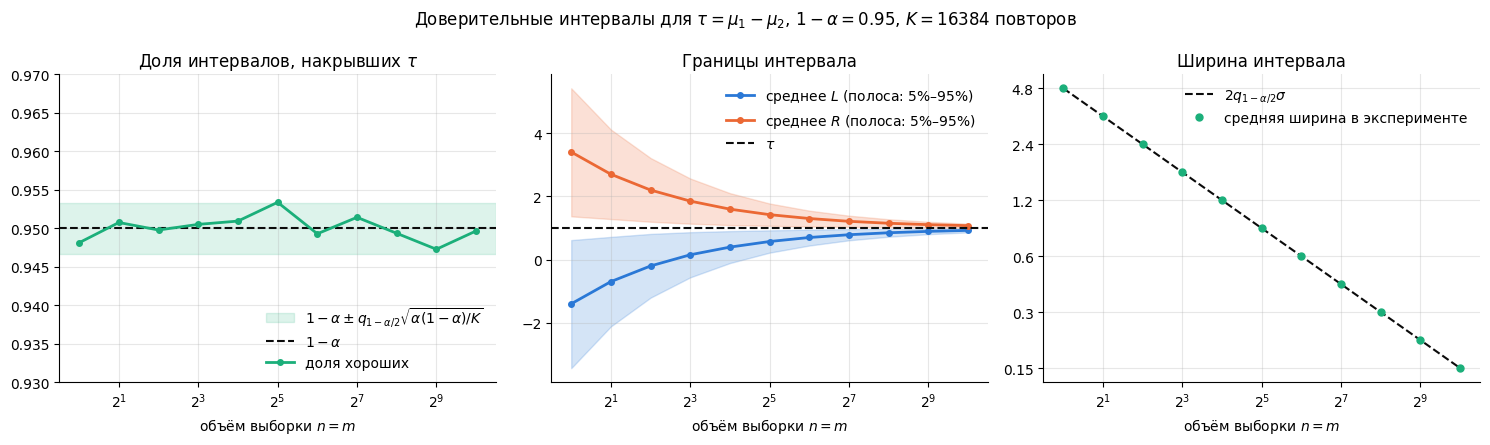

In [3]:
colors = {"low": "#2a78d6", "high": "#eb6834", "coverage": "#1baf7a", "truth": "#0b0b0b"}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

ax = axes[0]
ax.axhspan(1 - alpha - q * coverage_std, 1 - alpha + q * coverage_std, color=colors["coverage"], alpha=0.15,
           label=r"$1 - \alpha \pm q_{1-\alpha/2} \sqrt{\alpha(1-\alpha)/K}$")
ax.axhline(1 - alpha, color=colors["truth"], linestyle="--", linewidth=1.5, label=r"$1 - \alpha$")
ax.plot(sample_sizes, coverage, color=colors["coverage"], linewidth=2, marker="o", markersize=4, label="доля хороших")
ax.set_xscale("log", base=2)
ax.set_ylim(1 - alpha - 0.02, 1 - alpha + 0.02)
ax.set_xlabel("объём выборки $n = m$")
ax.set_title(r"Доля интервалов, накрывших $\tau$")
ax.legend(frameon=False, loc="lower right")

ax = axes[1]
for name, bound, label in (("low", lows, "$L$"), ("high", highs, "$R$")):
    ax.fill_between(sample_sizes, np.quantile(bound, 0.05, axis=1), np.quantile(bound, 0.95, axis=1),
                    color=colors[name], alpha=0.2)
    ax.plot(sample_sizes, bound.mean(axis=1), color=colors[name], linewidth=2, marker="o", markersize=4,
            label=f"среднее {label} (полоса: 5%–95%)")
ax.axhline(tau, color=colors["truth"], linestyle="--", linewidth=1.5, label=r"$\tau$")
ax.set_xscale("log", base=2)
ax.set_xlabel("объём выборки $n = m$")
ax.set_title("Границы интервала")
ax.legend(frameon=False)

ax = axes[2]
sizes = np.array(sample_sizes)
ax.plot(sizes, 2 * q * np.sqrt(var1 / sizes + var2 / sizes), color=colors["truth"], linestyle="--", linewidth=1.5,
        label=r"$2 q_{1-\alpha/2} \sigma$")
ax.plot(sample_sizes, (highs - lows).mean(axis=1), color=colors["coverage"], linewidth=0, marker="o", markersize=5,
        label="средняя ширина в эксперименте")
ax.set_xscale("log", base=2)
ax.set_yscale("log")
ax.set_yticks([0.15, 0.3, 0.6, 1.2, 2.4, 4.8], labels=["0.15", "0.3", "0.6", "1.2", "2.4", "4.8"])
ax.minorticks_off()
ax.set_xlabel("объём выборки $n = m$")
ax.set_title("Ширина интервала")
ax.legend(frameon=False)

for ax in axes:
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle(rf"Доверительные интервалы для $\tau = \mu_1 - \mu_2$, $1 - \alpha = {1 - alpha}$, $K = {n_samples}$ повторов")
fig.tight_layout()
plt.show()

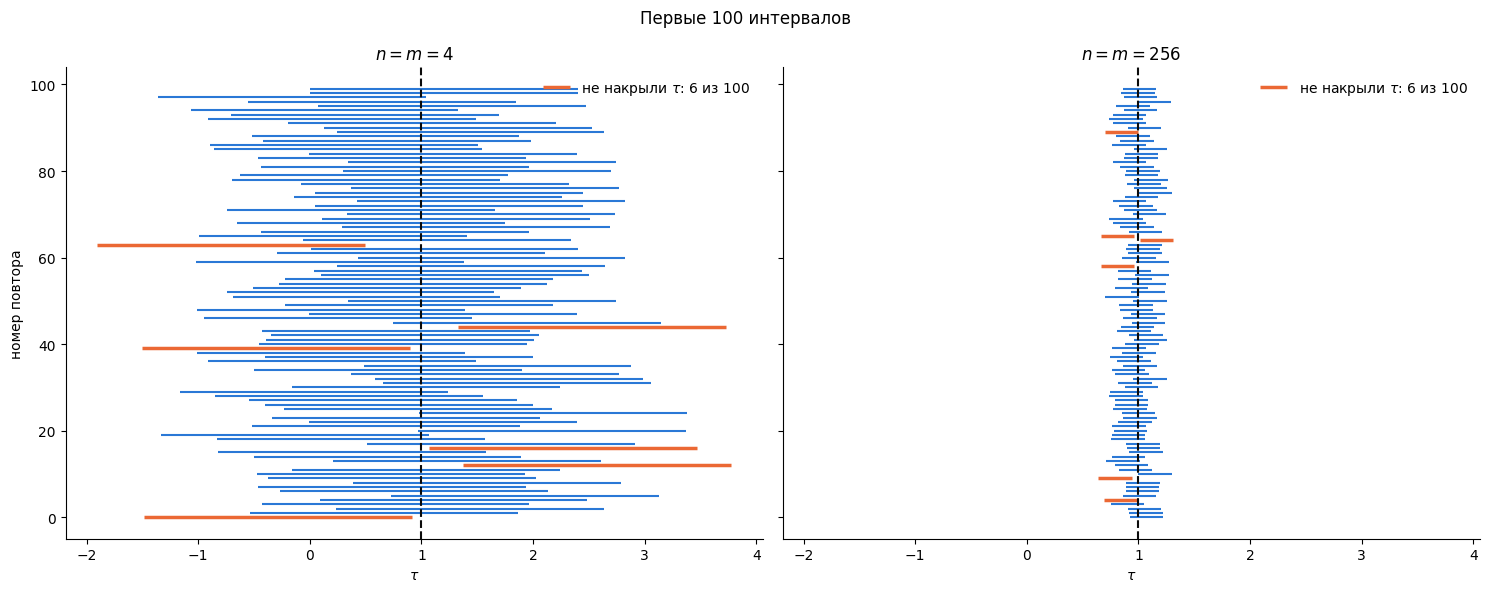

In [4]:
shown_sizes = [4, 256]
n_shown = 100

fig, axes = plt.subplots(1, len(shown_sizes), figsize=(15, 6), sharex=True, sharey=True)
for ax, size in zip(axes, shown_sizes):
    i = sample_sizes.index(size)
    good = covered[i, :n_shown]
    ys = np.arange(n_shown)
    ax.hlines(ys[good], lows[i, :n_shown][good], highs[i, :n_shown][good], color=colors["low"], linewidth=1.5)
    ax.hlines(ys[~good], lows[i, :n_shown][~good], highs[i, :n_shown][~good], color=colors["high"], linewidth=2.5,
              label=rf"не накрыли $\tau$: {(~good).sum()} из {n_shown}")
    ax.axvline(tau, color=colors["truth"], linestyle="--", linewidth=1.5)
    ax.set_title(f"$n = m = {size}$")
    ax.set_xlabel(r"$\tau$")
    ax.legend(frameon=False, loc="upper right")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("номер повтора")
fig.suptitle(f"Первые {n_shown} интервалов")
fig.tight_layout()
plt.show()

## Задание 2

*Вариант $5 = (4+6+4+9+9+1+4+6+6+3+1+1)\ \%\ 5 + 1$*.

### Теоретическая часть

Пусть $X_1, X_2, \dots X_n$ - выборка из $\mathrm{Pois}(\lambda)$.

$\mathbb{E}(X) = \mathrm{Var}(X) = \lambda$.

Оцениваемый параметр - второй начальный момент: $\theta = \mathbb{E}(X^2) = \mathrm{Var}(X) + (\mathbb{E}(X))^2 = \lambda + \lambda^2 \eqqcolon g(\lambda)$.

Заметим, что $g$ - гладкая и $g'(\lambda) = 1 + 2\lambda$ (для дельта-метода ниже).

#### Первый интервал (используя асимптотическую нормальность выборочного среднего)

Асимптотическая нормальность выборочного среднего: $\sqrt{n} (\overline{X} - \mathbb{E}(X)) \overset{d}{\to} \mathcal{N}(0, \mathrm{Var}(X)) \Leftrightarrow \sqrt{n} (\overline{X} - \lambda) \overset{d}{\to} \mathcal{N}(0, \lambda)$.

По дельта-методу $\sqrt{n} (g(\overline{X}) - g(\lambda)) \overset{d}{\to} \mathcal{N}(0, g'(\lambda) \lambda g'(\lambda)) \Leftrightarrow \dfrac{\sqrt{n} (g(\overline{X}) - \theta)}{\sqrt{\lambda} (1 + 2\lambda)} \overset{d}{\to} \mathcal{N}(0, 1)$.

$\overline{X}$ - состоятельная оценка $\mathbb{E}(X) = \lambda \Rightarrow$ по лемме Слуцкого в знаменателе можно заменить $\lambda$ на $\overline{X}$: $\dfrac{\sqrt{n} (g(\overline{X}) - \theta)}{\sqrt{\overline{X}} (1 + 2\overline{X})} \overset{d}{\to} \mathcal{N}(0, 1)$.

Пусть $q$ - квантиль стандартного нормального распределения, тогда $\displaystyle\lim_{n \to \infty} P(q_{\frac{\alpha}{2}} < \dfrac{\sqrt{n} (g(\overline{X}) - \theta)}{\sqrt{\overline{X}} (1 + 2\overline{X})} < q_{1 - \frac{\alpha}{2}}) = 1 - \alpha$.

$q_{\frac{\alpha}{2}} < \dfrac{\sqrt{n} (g(\overline{X}) - \theta)}{\sqrt{\overline{X}} (1 + 2\overline{X})} < q_{1 - \frac{\alpha}{2}} \Leftrightarrow q_{\frac{\alpha}{2}} \sqrt{\overline{X}} (1 + 2\overline{X}) \dfrac{1}{\sqrt{n}} < g(\overline{X}) - \theta < q_{1 - \frac{\alpha}{2}} \sqrt{\overline{X}} (1 + 2\overline{X}) \dfrac{1}{\sqrt{n}} \Leftrightarrow g(\overline{X}) - q_{\frac{\alpha}{2}} \sqrt{\overline{X}} (1 + 2\overline{X}) \dfrac{1}{\sqrt{n}} > \theta > g(\overline{X}) - q_{1 - \frac{\alpha}{2}} \sqrt{\overline{X}} (1 + 2\overline{X}) \dfrac{1}{\sqrt{n}}$.

Так как $q_{\frac{\alpha}{2}} = -q_{1 - \frac{\alpha}{2}}$, то имеем $\theta \in g(\overline{X}) \pm q_{1 - \frac{\alpha}{2}} \sqrt{\dfrac{\overline{X}}{n}} (1 + 2\overline{X}) \eqqcolon I_{\overline{X}}$ - требуемый асимптотический доверительный интервал уровня $1 - \alpha$.

#### Второй интервал (используя асимптотическую нормальность дисперсии)

Асимптотическая нормальность дисперсии ($\mu_4$ - 4 центральный момент): $\sqrt{n} (S_n^2 - \mathbb{Var}(X)) \overset{d}{\to} \mathcal{N}(0, \mu_4 - \mathrm{Var}(X)^2) \Leftrightarrow \sqrt{n} (S_n^2 - \lambda) \overset{d}{\to} \mathcal{N}(0, \lambda + 3 \lambda^2 - \lambda^2) \Leftrightarrow \sqrt{n} (S_n^2 - \lambda) \overset{d}{\to} \mathcal{N}(0, \lambda + 2 \lambda^2)$.

По дельта-методу $\sqrt{n} (g(S_n^2) - g(\lambda)) \overset{d}{\to} \mathcal{N}(0, g'(\lambda) (\lambda + 2 \lambda^2) g'(\lambda)) \Leftrightarrow \dfrac{\sqrt{n} (g(S_n^2) - \theta)}{\sqrt{\lambda + 2 \lambda^2} (1 + 2\lambda)} \overset{d}{\to} \mathcal{N}(0, 1) \Leftrightarrow \dfrac{\sqrt{n} (g(S_n^2) - \theta)}{\sqrt{\lambda} (1 + 2\lambda)^{1.5}} \overset{d}{\to} \mathcal{N}(0, 1)$.

$S_n^2$ - состоятельная оценка $\mathbb{Var}(X) = \lambda \Rightarrow$ по лемме Слуцкого в знаменателе можно заменить $\lambda$ на $S_n^2$: $\dfrac{\sqrt{n} (g(S_n^2) - \theta)}{\sqrt{S_n^2} (1 + 2 S_n^2)^{1.5}} \overset{d}{\to} \mathcal{N}(0, 1)$.

Аналогично имеем $\theta \in g(S_n^2) \pm q_{1 - \frac{\alpha}{2}} \sqrt{\dfrac{S_n^2}{n}} (1 + 2 S_n^2)^{1.5} \eqqcolon I_{S_n^2}$ - требуемый асимптотический доверительный интервал уровня $1 - \alpha$.

Заметим, что т.к. $S_n^2$ и $\overline{X}$ - состоятельные оценки $\lambda$, то $\dfrac{|I_{S_n^2}|}{|I_{\overline{X}}|} \overset{\mathbb{P}}{\to} \dfrac{2 q_{1 - \frac{\alpha}{2}} \sqrt{\dfrac{\lambda}{n}} (1 + 2 \lambda)^{1.5}}{2 q_{1 - \frac{\alpha}{2}} \sqrt{\dfrac{\lambda}{n}} (1 + 2 \lambda)} = \sqrt{1 + 2 \lambda}$.

В эксперименте далее $\lambda = 1$ (по условию) $\Rightarrow \dfrac{|I_{S_n^2}|}{|I_{\overline{X}}|} \overset{\mathbb{P}}{\to} \sqrt{3}$.

### Практическая часть

Для каждого объёма выборки $n \in \{2^0, 2^1, \dots, 2^{10}\}$ генерируем $K = 16384$ независимых выборок из $\mathrm{Pois}(1)$. Для каждой выборки строим оба асимптотических доверительных интервала уровня $1 - \alpha = 0.95$ из теоретической части. Истинный второй начальный момент $\theta = 1 + 1^2 = 2$. Как и в первом задании, фиксируем начальное состояние генератора и считаем, что интервал накрыл параметр, если $L < \theta < R$.

In [12]:
alpha = 0.05
sample_sizes = [2**p for p in range(11)]
n_samples = 16384
lam = 1
theta = lam + lam**2
seed = 0x5dab69e0  # openssl rand -hex 4
rng_pois = np.random.default_rng(seed)
methods = ("по среднему", "по дисперсии")
shape = (len(sample_sizes), n_samples)
pois_lows = {method: np.empty(shape) for method in methods}
pois_highs = {method: np.empty(shape) for method in methods}

q = stats.norm.ppf(1 - alpha / 2)

for i, n in enumerate(sample_sizes):
    batch = max(1, 2**20 // n)
    for start in range(0, n_samples, batch):
        rows = slice(start, min(start + batch, n_samples))
        x = rng_pois.poisson(lam, size=(rows.stop - start, n))
        mean = x.mean(axis=1)
        var = x.var(axis=1, ddof=0)
        for method, t, power in zip(methods, (mean, var), (1, 1.5)):
            center = t + t**2
            half_width = q * np.sqrt(t / n) * (1 + 2*t)**power
            pois_lows[method][i, rows] = center - half_width
            pois_highs[method][i, rows] = center + half_width

pois_covered = {}
pois_coverage = {}
pois_width = {}
for method in methods:
    left, right = pois_lows[method], pois_highs[method]
    pois_covered[method] = (left < theta) & (theta < right)
    pois_coverage[method] = pois_covered[method].mean(axis=1)
    pois_width[method] = (right - left).mean(axis=1)

pois_coverage_std = math.sqrt(alpha * (1 - alpha) / n_samples)

print(f"1 - alpha = {1 - alpha}, ожидаемый разброс доли: ±{q * pois_coverage_std:.4f} (уровень {1 - alpha})")
print(f"{'n':>5} {'интервал':>13}{'доля хороших':>14}{'ширина':>10}{'E L':>10}{'E R':>10}{'sd L':>10}{'sd R':>10}")
for i, n in enumerate(sample_sizes):
    for method in methods:
        left, right = pois_lows[method][i], pois_highs[method][i]
        print(f"{n:5} {method:>13}{pois_coverage[method][i]:14.4f}{pois_width[method][i]:10.4f}"
              f"{left.mean():10.4f}{right.mean():10.4f}{left.std():10.4f}{right.std():10.4f}")

1 - alpha = 0.95, ожидаемый разброс доли: ±0.0033 (уровень 0.95)
    n      интервал  доля хороших    ширина       E L       E R      sd L      sd R
    1   по среднему        0.6305   13.9405   -3.9262   10.0143    3.9209   12.3413
    1  по дисперсии        0.0000    0.0000    0.0000    0.0000    0.0000    0.0000
    2   по среднему        0.8667    9.0383   -2.0383    6.9999    1.2326    6.2175
    2  по дисперсии        0.2620    9.5931   -3.5053    6.0879    9.8177   16.9644
    4   по среднему        0.9096    6.1882   -0.8374    5.3508    0.2224    3.4537
    4  по дисперсии        0.6316    9.4974   -2.9260    6.5714    5.1693   11.4998
    8   по среднему        0.9031    4.2819   -0.0061    4.2759    0.2518    1.9772
    8  по дисперсии        0.7921    7.1787   -1.6226    5.5562    1.8344    6.1895
   16   по среднему        0.9234    2.9779    0.5730    3.5509    0.3358    1.1925
   16  по дисперсии        0.8335    5.1030   -0.5618    4.5412    0.4180    3.2915
   32   по 

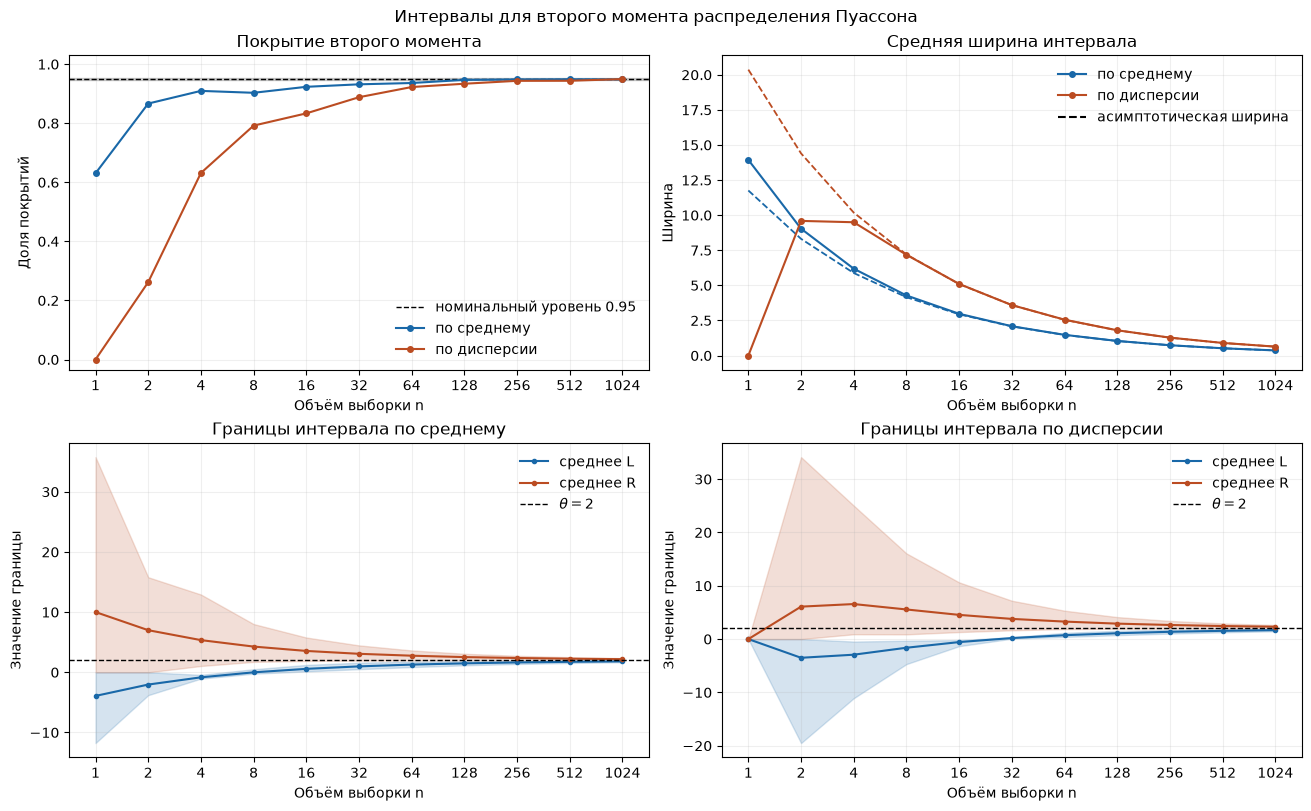

In [19]:
sizes_pois = np.array(sample_sizes)
method_colors = ("#1968a8", "#bb4c22")
fig, axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
ax_cov, ax_width = axes[0]
nominal = 1 - alpha
band = q * np.sqrt(nominal * (1 - nominal) / n_samples)
ax_cov.axhspan(nominal - band, nominal + band, color="grey", alpha=0.35)
ax_cov.axhline(nominal, color="black", ls="--", lw=1, label="номинальный уровень 0.95")
for method, color, factor in zip(methods, method_colors, (1, np.sqrt(3))):
    ax_cov.plot(sizes_pois, pois_coverage[method], "o-", ms=4, color=color, label=method)
    ax_width.plot(sizes_pois, pois_width[method], "o-", ms=4, color=color, label=method)
    ax_width.plot(sizes_pois, 6*q*factor / np.sqrt(sizes_pois), "--", lw=1.3, color=color)
ax_width.plot([], [], "k--", label="асимптотическая ширина")
ax_cov.set(title="Покрытие второго момента", ylabel="Доля покрытий", ylim=(-0.035, 1.03))
ax_width.set(title="Средняя ширина интервала", ylabel="Ширина")
for ax, method in zip(axes[1], methods):
    for bound, color, name in ((pois_lows[method], "#1968a8", "L"), (pois_highs[method], "#bb4c22", "R")):
        lo, hi = np.quantile(bound, [0.05, 0.95], axis=1)
        ax.fill_between(sizes_pois, lo, hi, color=color, alpha=0.18)
        ax.plot(sizes_pois, bound.mean(axis=1), "o-", ms=3, color=color, label=f"среднее {name}")
    ax.axhline(theta, color="black", ls="--", lw=1, label=r"$\theta = 2$")
    ax.set(title=f"Границы интервала {method}", ylabel="Значение границы")
for ax in axes.flat:
    ax.set_xscale("log", base=2)
    ax.set_xticks(sizes_pois, labels=sizes_pois)
    ax.set_xlabel("Объём выборки n")
    ax.grid(alpha=0.2)
    ax.legend(frameon=False)
fig.suptitle("Интервалы для второго момента распределения Пуассона")
plt.show()

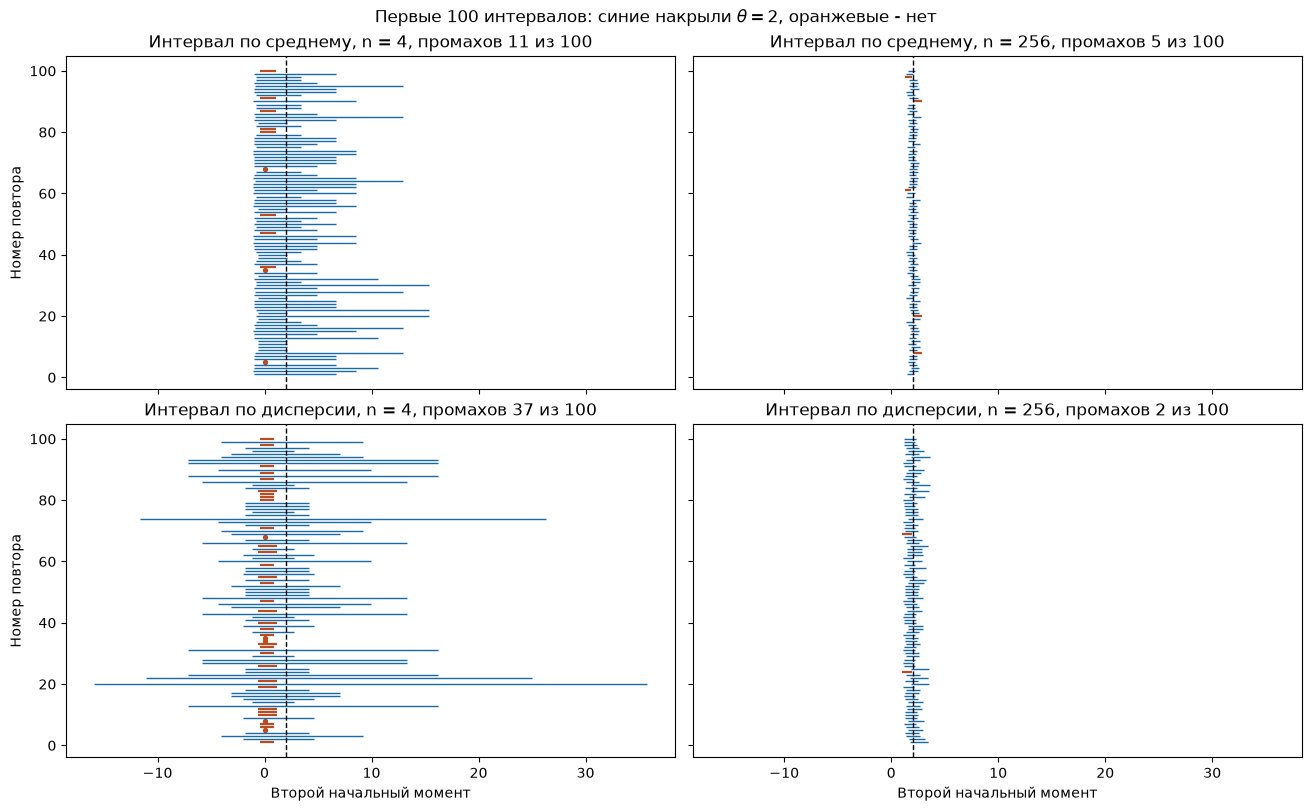

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True, sharey=True, constrained_layout=True)
n_show = 100
repeat = np.arange(1, n_show + 1)
for row, method in enumerate(methods):
    for col, n in enumerate((4, 256)):
        ax = axes[row, col]
        i = sample_sizes.index(n)
        left = pois_lows[method][i, :n_show]
        right = pois_highs[method][i, :n_show]
        good = pois_covered[method][i, :n_show]
        ax.hlines(repeat[good], left[good], right[good], color="#1968a8", lw=1)
        ax.hlines(repeat[~good], left[~good], right[~good], color="#bb4c22", lw=1.6)
        zero = left == right
        ax.scatter(left[zero], repeat[zero], color="#bb4c22", s=8)
        ax.axvline(theta, color="black", ls="--", lw=1)
        ax.set_title(f"Интервал {method}, n = {n}, промахов {sum(~good)} из {n_show}")
        if col == 0:
            ax.set_ylabel("Номер повтора")
        if row == 1:
            ax.set_xlabel("Второй начальный момент")
fig.suptitle(r"Первые 100 интервалов: синие накрыли $\theta = 2$, оранжевые - нет")
plt.show()